In [1]:
import numpy as np

# 배치 경사하강법에 의한 퍼셉트론 모델
class PerceptronGD(object):
    """
    매개변수
    ------------
    eta : float
      학습률 (0.0과 1.0 사이)
    n_iter : int
      훈련 데이터셋 반복 횟수
    random_state : int
      가중치 무작위 초기화를 위한 난수 생성기 시드

    속성
    -----------
    w_ : 1d-array
      학습된 가중치
    cost_ : list
      에포크마다 누적된 비용 함수의 제곱합

    """
    def __init__(self, eta=0.01, n_iter=50, random_state=1):
        self.eta = eta
        self.n_iter = n_iter
        self.random_state = random_state

    def fit(self, X, y):
        """훈련 데이터 학습

        매개변수
        ----------
        X : array-like, shape = [n_samples, n_features]
          n_samples 개의 샘플과 n_features 개의 특성으로 이루어진 훈련 데이터
        y : array-like, shape = [n_samples]
          타깃값

        반환값
        -------
        self : object

        """
        rgen = np.random.RandomState(self.random_state) # random seed
        # 가중치 초기화
        self.w_ = rgen.normal(loc=0.0, scale=0.01, size=1 + X.shape[1])
        self.cost_ = [] # 오차함수(비용함수)값을 저장하기 위한 리스트

        for i in range(self.n_iter):
            net_input = self.net_input(X)
            output = self.activation(net_input)

            errors = (y - output)   # 출력의 오차 = 정답 - 출력
            # 가중치 업데이트
            self.w_[1:] += self.eta * X.T.dot(errors)
            self.w_[0] += self.eta * errors.sum()

            cost = (errors**2).sum() / 2.0 # 평균제곱오차
            self.cost_.append(cost) # 오차 값 리스트에 저장
        return self

    def net_input(self, X):
        """가중합 연산"""
        return np.dot(X, self.w_[1:]) + self.w_[0]

    def activation(self, X):
        """활성화 함수(선형 활성화 함수)"""
        return X

    def predict(self, X):
        """단위 계단 함수를 사용하여 클래스 레이블을 반환"""
        return np.where(self.activation(self.net_input(X)) >= 0.0, 1, -1)

In [2]:
import os
import pandas as pd

s = 'https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data'
print('URL:', s)

df = pd.read_csv(s, header=None, encoding='utf-8')
df.tail() # 마지막 5개의 데이터를 출력

URL: https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data


,0,1,2,3,4
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica
149,5.9,3.0,5.1,1.8,Iris-virginica


In [3]:
import numpy as np

# setosa와 versicolor를 선택
y = df.iloc[0:100, 4].values   # index 0~99 까지 데이터의 5번째 열의 값을 가져온다
y = np.where(y == 'Iris-setosa', -1, 1) # Iris-Setosa 는 -1, 나머지는 1 로 레이블링

# 꽃받침 길이와 꽃잎 길이를 추출
X = df.iloc[0:100, [0, 2]].values # index 0~99 까지 데이터의 1번째 3번째 열의 값을 가져온다

In [4]:
X[48:52] # 인덱스 48~51 까지 입력 데이터 (49번째 ~ 52번째 데이터) 출력

array([[5.3, 1.5],
       [5. , 1.4],
       [7. , 4.7],
       [6.4, 4.5]])

In [5]:
y[48:52] # 인덱스 48~51 까지 타겟 데이터 (49번째 ~ 52번째 데이터) 출력

array([-1, -1,  1,  1])

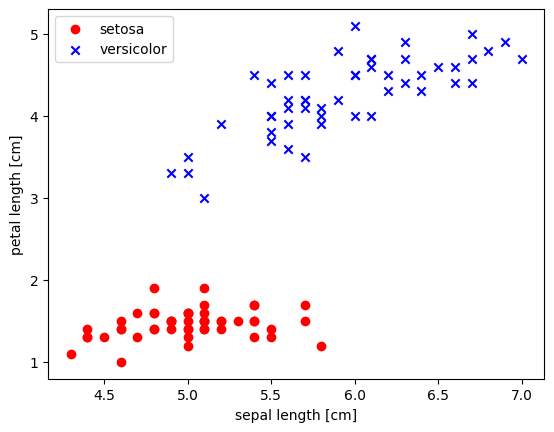

In [6]:
%matplotlib inline
import matplotlib.pyplot as plt

# 산점도를 그립니다, setosa-음성(red), versicolor-양성(versicolor)
plt.scatter(X[:50, 0], X[:50, 1],
            color='red', marker='o', label='setosa')
plt.scatter(X[50:100, 0], X[50:100, 1],
            color='blue', marker='x', label='versicolor')

plt.xlabel('sepal length [cm]')
plt.ylabel('petal length [cm]')
plt.legend(loc='upper left')

plt.show()

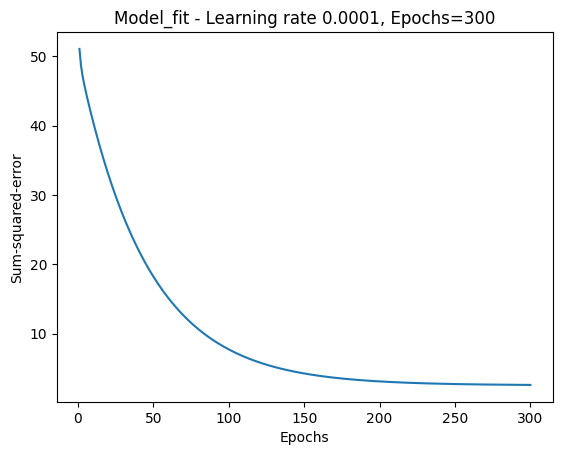

In [7]:
# 퍼셉트론 모델 학습
# 반복횟수: 300, 학습률: 0.0001
model_fit = PerceptronGD(n_iter=300, eta=0.0001).fit(X, y)

# 학습 진행에 따른 오차함수 값 plot
plt.plot(range(1, len(model_fit.cost_) + 1), model_fit.cost_)
plt.xlabel('Epochs')
plt.ylabel('Sum-squared-error')
plt.title('Model_fit - Learning rate 0.0001, Epochs=300')
plt.show()

In [8]:
# 학습으로 얻게된 가중치(w_0 ~ w_2)
model_fit.w_

array([-0.13272805, -0.38338316,  0.78258541])

In [9]:
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore', category=UserWarning)


def plot_decision_regions(X, y, classifier, test_idx=None, resolution=0.02):

    # 마커와 컬러맵을 설정합니다.
    markers = ('s', 'x', 'o', '^', 'v')
    colors = ('red', 'blue', 'lightgreen', 'gray', 'cyan')
    cmap = ListedColormap(colors[:len(np.unique(y))])

    # 결정 경계를 그립니다.
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))
    Z = classifier.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    Z = Z.reshape(xx1.shape)
    plt.contourf(xx1, xx2, Z, alpha=0.3, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    for idx, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y == cl, 0],
                    y=X[y == cl, 1],
                    alpha=0.8,
                    c=colors[idx],
                    marker=markers[idx],
                    label=cl,
                    edgecolor='black')

    # 테스트 샘플을 부각하여 그립니다.
    if test_idx:
        # 모든 샘플을 그립니다.
        X_test, y_test = X[test_idx, :], y[test_idx]

        plt.scatter(X_test[:, 0],
                    X_test[:, 1],
                    facecolor='none',
                    edgecolor='black',
                    alpha=1.0,
                    linewidth=1,
                    marker='o',
                    s=100,
                    label='test set')

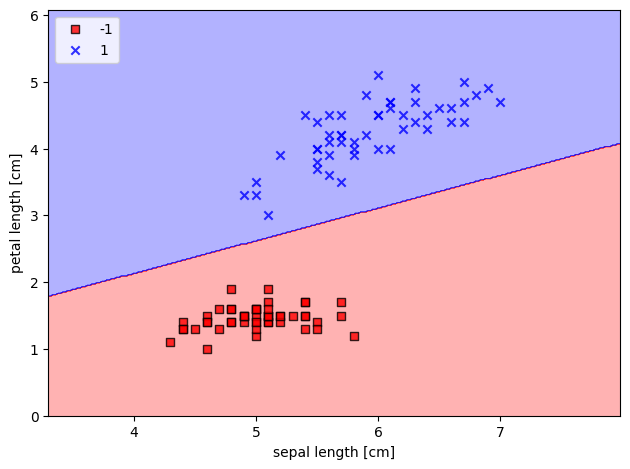

In [10]:
plot_decision_regions(X, y, classifier=model_fit)
plt.xlabel('sepal length [cm]')
plt.ylabel('petal length [cm]')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

In [11]:
# model 1
model1 = PerceptronGD(n_iter=10, eta=0.01).fit(X, y)

# model 2
model2 = PerceptronGD(n_iter=10, eta=0.0001).fit(X, y)

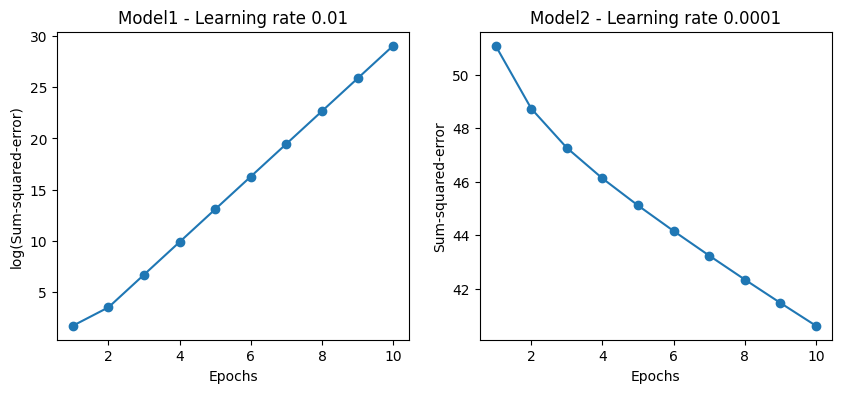

In [12]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

ax[0].plot(range(1, len(model1.cost_) + 1), np.log10(model1.cost_), marker='o')
ax[0].set_xlabel('Epochs')
ax[0].set_ylabel('log(Sum-squared-error)')
ax[0].set_title('Model1 - Learning rate 0.01')

ax[1].plot(range(1, len(model2.cost_) + 1), model2.cost_, marker='o')
ax[1].set_xlabel('Epochs')
ax[1].set_ylabel('Sum-squared-error')
ax[1].set_title('Model2 - Learning rate 0.0001')

plt.show()

In [13]:
# 데이터 전처리: 표준화(standardization)
X_std = np.copy(X)

# 첫번째 특징에 대한 평균과 표준편차를 구하여 첫번째 특징 표준화
X_std[:, 0] = (X[:,0] - X[:,0].mean()) / X[:,0].std()
# 두번째 특징에 대한 평균과 표준편차를 구하여 첫번째 특징 표준화
X_std[:, 1] = (X[:,1] - X[:,1].mean()) / X[:,1].std()

In [14]:
model_std = PerceptronGD(n_iter=15, eta=0.01)
model_std.fit(X_std, y)

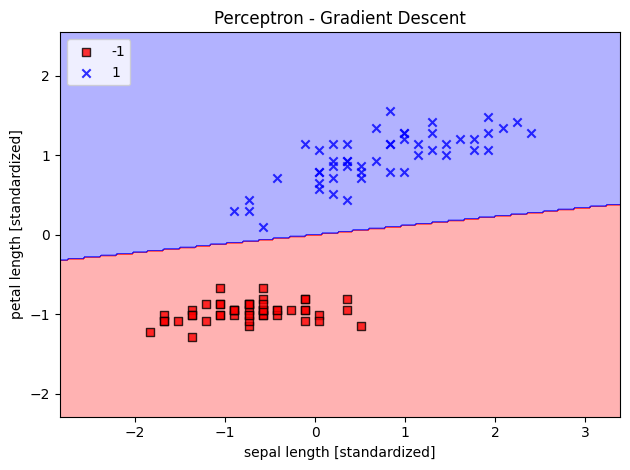

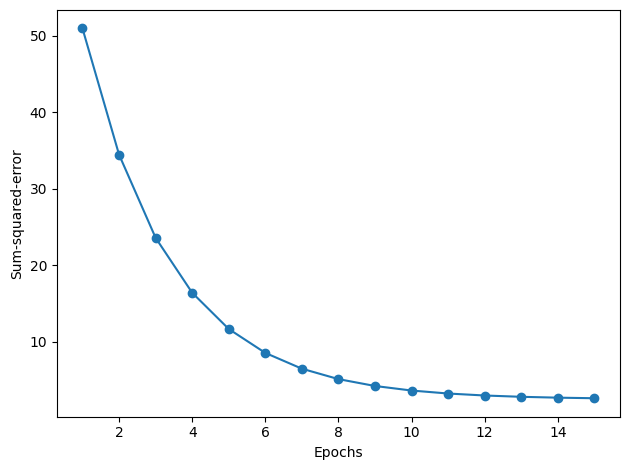

In [15]:
# week3_1.txt
plot_decision_regions(X_std, y, classifier=model_std)
plt.title('Perceptron - Gradient Descent')
plt.xlabel('sepal length [standardized]')
plt.ylabel('petal length [standardized]')
plt.legend(loc='upper left')
plt.tight_layout()
# plt.savefig('images/02_14_1.png', dpi=300)
plt.show()

plt.plot(range(1, len(model_std.cost_) + 1), model_std.cost_, marker='o')
plt.xlabel('Epochs')
plt.ylabel('Sum-squared-error')

plt.tight_layout()
# plt.savefig('images/02_14_2.png', dpi=300)
plt.show()

In [16]:
# 확률적 경사하강법에 의한 퍼셉트론 모델
class PerceptronSGD(object):
    """
    Parameters
    ------------
    eta : float
      학습률 (0.0과 1.0 사이)
    n_iter : int
      훈련 데이터셋 반복 횟수
    shuffle : bool (default: True)
      True로 설정하면 같은 반복이 되지 않도록 에포크마다 훈련 데이터를 섞습니다
    random_state : int
      가중치 무작위 초기화를 위한 난수 생성기 시드

    Attributes
    -----------
    w_ : 1d-array
      학습된 가중치
    cost_ : list
      모든 훈련 샘플에 대해 에포크마다 누적된 평균 비용 함수의 제곱합

    """
    def __init__(self, eta=0.01, n_iter=10, shuffle=True, random_state=None):
        self.eta = eta
        self.n_iter = n_iter
        self.w_initialized = False
        self.shuffle = shuffle
        self.random_state = random_state

    def fit(self, X, y):
        """훈련 데이터 학습
        Parameters
        ----------
        X : {array-like}, shape = [n_samples, n_features]
          n_samples 개의 샘플과 n_features 개의 특성으로 이루어진 훈련 데이터
        y : array-like, shape = [n_samples]
          타깃 벡터

        반환값
        -------
        self : object

        """
        self._initialize_weights(X.shape[1])
        self.cost_ = []
        for i in range(self.n_iter):
            if self.shuffle:
                X, y = self._shuffle(X, y)

            cost = []

            for xi, target in zip(X, y):
                cost.append(self._update_weights(xi, target))

            avg_cost = sum(cost) / len(y)
            self.cost_.append(avg_cost)

        return self

    def partial_fit(self, X, y):
        """가중치를 다시 초기화하지 않고 훈련 데이터를 학습"""
        # 가중치가 초기화하지 않된 경우 가중치를 초기화
        if not self.w_initialized:
            self._initialize_weights(X.shape[1])

        if y.ravel().shape[0] > 1:
            for xi, target in zip(X, y):
                self._update_weights(xi, target)
        else:
            self._update_weights(X, y)
        return self

    def _shuffle(self, X, y):
        """훈련 데이터 Shuffle """
        r = self.rgen.permutation(len(y)) # 무작위 인덱스 생성
        return X[r], y[r] # 무작위로 추출된 인덱스로 X, y 리턴

    def _initialize_weights(self, m):
        """랜덤한 작은 수로 가중치를 초기화"""
        self.rgen = np.random.RandomState(self.random_state)
        self.w_ = self.rgen.normal(loc=0.0, scale=0.01, size=1 + m)
        self.w_initialized = True

    def _update_weights(self, xi, target):
        """가중치를 업데이트"""
        output = self.activation(self.net_input(xi))
        error = (target - output)
        self.w_[1:] += self.eta * xi.dot(error)
        self.w_[0] += self.eta * error
        cost = 0.5 * error**2
        return cost

    def net_input(self, X):
        """가중합 연산"""
        return np.dot(X, self.w_[1:]) + self.w_[0]

    def activation(self, X):
        """활성화 함수(선형 활성화) 연산"""
        return X

    def predict(self, X):
        """단위 계단 함수를 사용하여 클래스 레이블을 반환"""
        return np.where(self.activation(self.net_input(X)) >= 0.0, 1, -1)

In [17]:
model_sgd = PerceptronSGD(n_iter=15, eta=0.01, random_state=1)
model_sgd.fit(X_std, y)
# 가중치 출력
model_sgd.w_

array([ 2.27202773e-04, -1.38544756e-01,  1.07263215e+00])

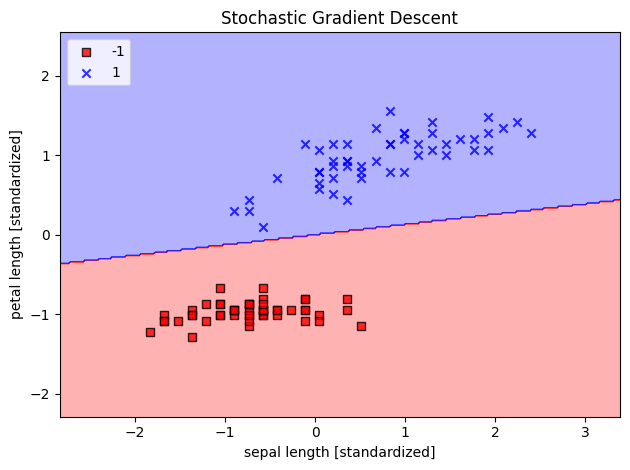

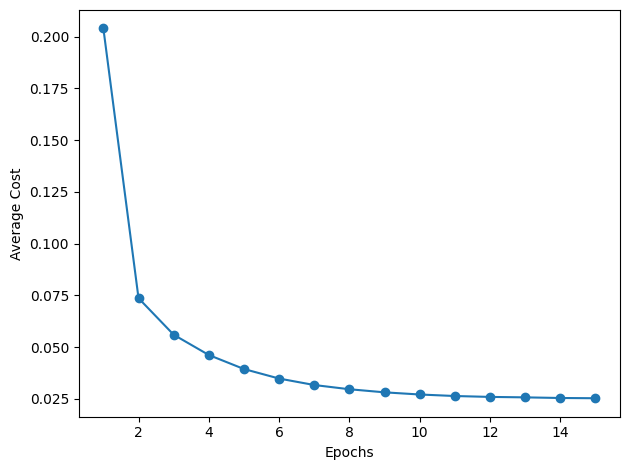

In [18]:
# week3_2.txt
plot_decision_regions(X_std, y, classifier=model_sgd)
plt.title('Stochastic Gradient Descent')
plt.xlabel('sepal length [standardized]')
plt.ylabel('petal length [standardized]')
plt.legend(loc='upper left')

plt.tight_layout()
# plt.savefig('images/02_15_1.png', dpi=300)
plt.show()

plt.plot(range(1, len(model_sgd.cost_) + 1), model_sgd.cost_, marker='o')
plt.xlabel('Epochs')
plt.ylabel('Average Cost')

plt.tight_layout()
# plt.savefig('images/02_15_2.png', dpi=300)
plt.show()

In [19]:
model_std.cost_ # 배치 경사하강법의 cost function 값 변화

[50.97692262073463,
 34.462945201633055,
 23.572819267222194,
 16.38559493990226,
 11.642197678719517,
 8.511668206880154,
 6.445593148344742,
 5.0820327072433775,
 4.182115219320866,
 3.5881910626368843,
 3.1962152330448785,
 2.937520500299579,
 2.766788124224707,
 2.654108813243642,
 2.579743145670435]

In [20]:
model_sgd.cost_   # 확률적 경사하강법의 cost function 값 변화

[0.20394456166031527,
 0.07361591599497302,
 0.05595915980120136,
 0.04616048513652026,
 0.03938451477733424,
 0.03477977825838302,
 0.03165721904186385,
 0.029612965517701775,
 0.028119851141872047,
 0.02707516502475462,
 0.026343115030327834,
 0.025908993480534156,
 0.025690816663739704,
 0.025388179942035065,
 0.025269618641442088]

In [21]:
from sklearn import datasets
import numpy as np

iris = datasets.load_iris() # 사이킷런에서 붓꽃 데이터셋을 적재

# 입력 벡터의 특징으로는 세 번째 열의 꽃잎의 길이, 네 번째 열의 꽃잎의 너비 선택
X = iris.data[:, [2, 3]]
y = iris.target

# 클래스는 이미 정수 레이블로 변환 되어 있음
# 0=Iris-Setosa, 1=Iris-Versicolor, 2=Iris-Virginica
print(y)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


In [22]:
# 70%는 훈련 데이터 30%는 테스트 데이터로 분할
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1, stratify=y)

print('y의 레이블 카운트:', np.bincount(y))
print('y_train의 레이블 카운트:', np.bincount(y_train))
print('y_test의 레이블 카운트:', np.bincount(y_test))

y의 레이블 카운트: [50 50 50]
y_train의 레이블 카운트: [35 35 35]
y_test의 레이블 카운트: [15 15 15]


In [23]:
# scikit-learn 을 이용한 데이터 전처리(표준화)
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
sc.fit(X_train)
X_train_std = sc.transform(X_train)
X_test_std = sc.transform(X_test)

In [24]:
# scikit-learn 을 이용한 퍼셉트론 모델 학습
from sklearn.linear_model import Perceptron

ppn = Perceptron(eta0=0.1, random_state=1)
ppn.fit(X_train_std, y_train)

,penalty,None
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,1000
,tol,0.001
,shuffle,True
,verbose,0
,eta0,0.1
,n_jobs,None
,random_state,1


In [25]:
y_pred = ppn.predict(X_test_std)
print('잘못 분류된 샘플 개수: %d' % (y_test != y_pred).sum())

잘못 분류된 샘플 개수: 1


In [26]:
# 모델의 성능 평가: accuracy(정확도) - 테스트 데이터
print('정확도: %.3f' % ppn.score(X_test_std, y_test))

from sklearn.metrics import accuracy_score
print('정확도: %.3f' % accuracy_score(y_test, y_pred))

정확도: 0.978
정확도: 0.978


In [27]:
# 학습 데이터에 대한 정확도
accuracy_score(ppn.predict(X_train_std), y_train)

0.9428571428571428

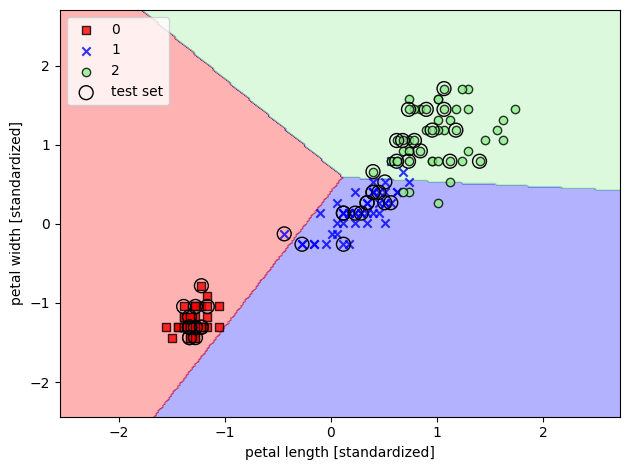

In [28]:
# week3_3.txt
X_combined_std = np.vstack((X_train_std, X_test_std))
y_combined = np.hstack((y_train, y_test))

plot_decision_regions(X=X_combined_std, y=y_combined,
                      classifier=ppn, test_idx=range(105, 150))
plt.xlabel('petal length [standardized]')
plt.ylabel('petal width [standardized]')
plt.legend(loc='upper left')

plt.tight_layout()
# plt.savefig('images/03_01.png', dpi=300)
plt.show()

In [29]:
# 로지스틱 회귀모델
class LogisticRegressionGD(object):
    """
    매개변수
    ------------
    eta : float
      학습률 (0.0과 1.0 사이)
    n_iter : int
      훈련 데이터셋 반복 횟수
    random_state : int
      가중치 무작위 초기화를 위한 난수 생성기 시드

    속성
    -----------
    w_ : 1d-array
      학습된 가중치
    cost_ : list
      에포크마다 누적된 비용 함수의 제곱합

    """
    def __init__(self, eta=0.01, n_iter=50, random_state=1):
        self.eta = eta
        self.n_iter = n_iter
        self.random_state = random_state

    def fit(self, X, y):
        """훈련 데이터 학습

        매개변수
        ----------
        X : array-like, shape = [n_samples, n_features]
          n_samples 개의 샘플과 n_features 개의 특성으로 이루어진 훈련 데이터
        y : array-like, shape = [n_samples]
          타깃값

        반환값
        -------
        self : object

        """
        rgen = np.random.RandomState(self.random_state) # random seed
        self.w_ = rgen.normal(loc=0.0, scale=0.01, size=1 + X.shape[1])
        self.cost_ = []

        for i in range(self.n_iter):
            net_input = self.net_input(X)
            output = self.activation(net_input)

            errors = (y - output)
            self.w_[1:] += self.eta * X.T.dot(errors)
            self.w_[0] += self.eta * errors.sum()

            # 오차 제곱합
            #cost = (errors**2).sum() / 2.0
            #self.cost_.append(cost)

            #오차 제곱합 대신 로지스틱 비용을 계산합니다.
            cost = -y.dot(np.log(output)) - ((1 - y).dot(np.log(1 - output)))
            self.cost_.append(cost)

        return self

    def net_input(self, X):
        """가중합 연산"""
        return np.dot(X, self.w_[1:]) + self.w_[0]

    def activation(self, z):
        """활성화 함수 연산"""
        return 1. / (1. + np.exp(-np.clip(z, -250, 250)))

    def predict(self, X):
        #"""단위 계단 함수를 사용하여 클래스 레이블을 반환합니다"""
        #return np.where(self.activation(self.net_input(X)) >= 0.0, 1, -1)

        """임계값(0.5)을 기준으로 레이블 0과 1로 반환"""
        return np.where(self.net_input(X) >= 0.0, 1, 0)

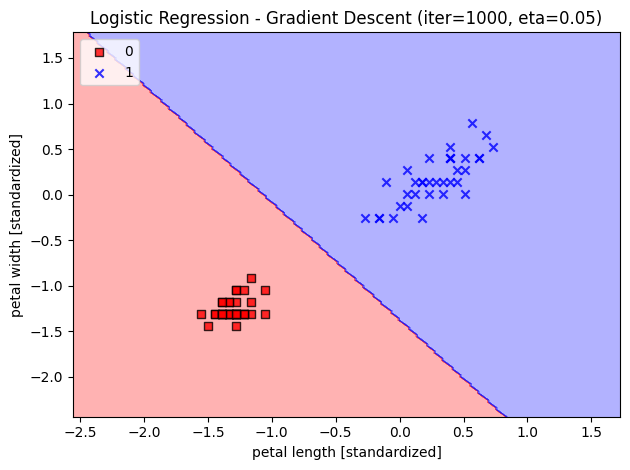

In [30]:
# 클래스 0, 1인 데이터만 추출, 훈련 데이터 75개 중 50개만 추출
X_train_01_subset = X_train_std[(y_train == 0) | (y_train == 1)]
y_train_01_subset = y_train[(y_train == 0) | (y_train == 1)]

lrgd = LogisticRegressionGD(eta=0.05, n_iter=1000, random_state=1)

lrgd.fit(X_train_01_subset, y_train_01_subset)

plot_decision_regions(X=X_train_01_subset,
                      y=y_train_01_subset,
                      classifier=lrgd)

plt.title('Logistic Regression - Gradient Descent (iter=1000, eta=0.05)')
plt.xlabel('petal length [standardized]')
plt.ylabel('petal width [standardized]')
plt.legend(loc='upper left')
plt.xlim()

plt.tight_layout()
plt.show()